# ЛР2. Клиент XML-RPC

Сначала запустите оба сервера, затем выполняйте ячейки клиента сверху вниз. После подготовки отдельные задания можно повторять независимо. Для обработки изображений сначала выполните загрузку исходного изображения.


## Подготовка: импорты, подключение и передача изображений

Для работы нужны основной XML-RPC сервис и отдельный сервис статистики. Здесь подключаются библиотеки, создаются подключения к сервисам и функции передачи изображений.


In [16]:
from datetime import datetime
from pathlib import Path
import pickle
import xmlrpc.client

import numpy as np
from PIL import Image
from IPython.display import display


project_directory = Path.cwd()
main_service = xmlrpc.client.ServerProxy('http://127.0.0.1:8008/RPC2', allow_none=True)
statistics_service = xmlrpc.client.ServerProxy('http://127.0.0.1:8018/RPC2', allow_none=True)


# NumPy-массив передается через Binary, потому что XML-RPC не поддерживает его напрямую.
def pack_image(image_array):
    return xmlrpc.client.Binary(pickle.dumps(image_array, protocol=pickle.HIGHEST_PROTOCOL))


def unpack_image(binary_image):
    return pickle.loads(binary_image.data)


def call_image_method(method_name, image_array, *method_arguments):
    binary_image_result = getattr(main_service, method_name)(pack_image(image_array), *method_arguments)
    return unpack_image(binary_image_result)


## Базовые методы из ЛР1

По условиям ЛР2 используется клиент и сервер из ЛР1. Эта ячейка демонстрирует сохранённые операции: проверку связи, сложение и возведение в степень.


In [19]:
print('Связь с сервером:', main_service.ping())
print('Сумма 2 и 3:', main_service.sum(2, 3))
print('2 в степени 3:', main_service.pow(2, 3))


Связь с сервером: True
Сумма 2 и 3: 5
2 в степени 3: 8


## Содержимое чёрного списка

Вспомогательный вывод для сдачи: показать все записи исходного CSV, чтобы выбирать входные данные прямо в ноутбуке. Отдельного требования выводить эту таблицу в методичке нет.


In [22]:
import pandas as pd

blacklist_table = pd.read_csv(project_directory / 'bad_boys2.csv', encoding='utf-8-sig').fillna('')
print('Всего записей в чёрном списке:', len(blacklist_table))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(blacklist_table)


Всего записей в чёрном списке: 5


,Surname,Name,Patronym,Birth,City,Position
0,Иванов,Иван,Иванович,22.03.1989,Москва,
1,Петров,Петр,Петрович,07.08.1985,Москва,инженер
2,Светлый,Михаил,Викторович,13.02.1992,Рязань,менеджер
3,Добрынин,Виталий,Александрович,15.04.1985,Ростов,
4,Скалина,Светлана,Алексеевна,19.11.1985,Москва,инженер


## Задание 1. Проверка чёрного списка

Требуется сравнивать ФИО без учёта регистра, допуская отличие на одну букву любого поля. При полном совпадении вернуть введённые данные и yes, при частичном — список похожих записей и similar, при отсутствии — введённые данные и no. В текущей реализации отличие допускается в одном поле ФИО; дата рождения должна совпасть. Буквы е и ё считаются равными.


In [25]:
# Проверяются точное совпадение, отличие на одну букву и отсутствие записи.
exact_blacklist_result = main_service.black_list_check('петров', 'ПЕТР', 'петрович', '07.08.1985')
similar_blacklist_result = main_service.black_list_check('Петро', 'Петр', 'Петрович', '07.08.1985')
missing_blacklist_result = main_service.black_list_check('Сидоров', 'Сидор', 'Сидорович', '01.01.2000')
print('Точное совпадение:', exact_blacklist_result)
print('Похожая запись:', similar_blacklist_result)
print('Отсутствующая запись:', missing_blacklist_result)


Точное совпадение: {'surname': 'петров', 'name': 'ПЕТР', 'patronym': 'петрович', 'birth': '07.08.1985', 'status': 'yes'}
Похожая запись: {'surname': 'Петро', 'name': 'Петр', 'patronym': 'Петрович', 'birth': '07.08.1985', 'status': 'similar', 'similar': [{'surname': 'Петров', 'name': 'Петр', 'patronym': 'Петрович', 'birth': '07.08.1985'}]}
Отсутствующая запись: {'surname': 'Сидоров', 'name': 'Сидор', 'patronym': 'Сидорович', 'birth': '01.01.2000', 'status': 'no'}


## Загрузка исходного изображения

Подготовить готовое изображение для операций обработки. Здесь загружается 11.bmp и выводится исходник для сравнения с результатами.


Исходное изображение


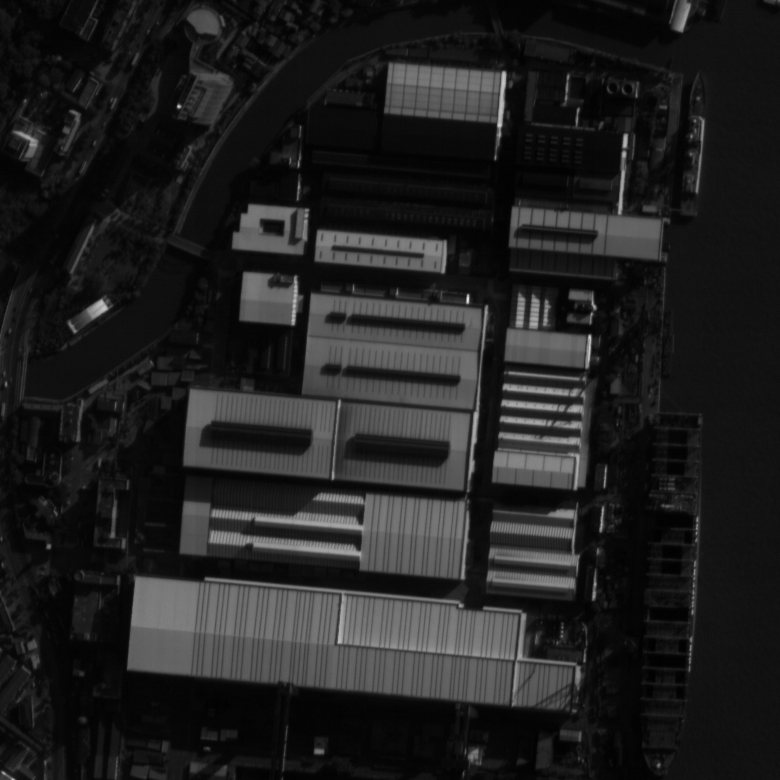

In [28]:
monochrome_image_path = project_directory / '11.bmp'
monochrome_image = np.array(Image.open(monochrome_image_path).convert('L'), dtype=np.uint8)[:, :, np.newaxis]
print('Исходное изображение')
display(Image.fromarray(monochrome_image[:, :, 0]))


## ЛР1. Инверсия изображения

Операция сохранена из ЛР1: заменить яркость каждого пикселя на 255 минус его исходное значение. Здесь показывается результат вызова сервера.


Инверсия


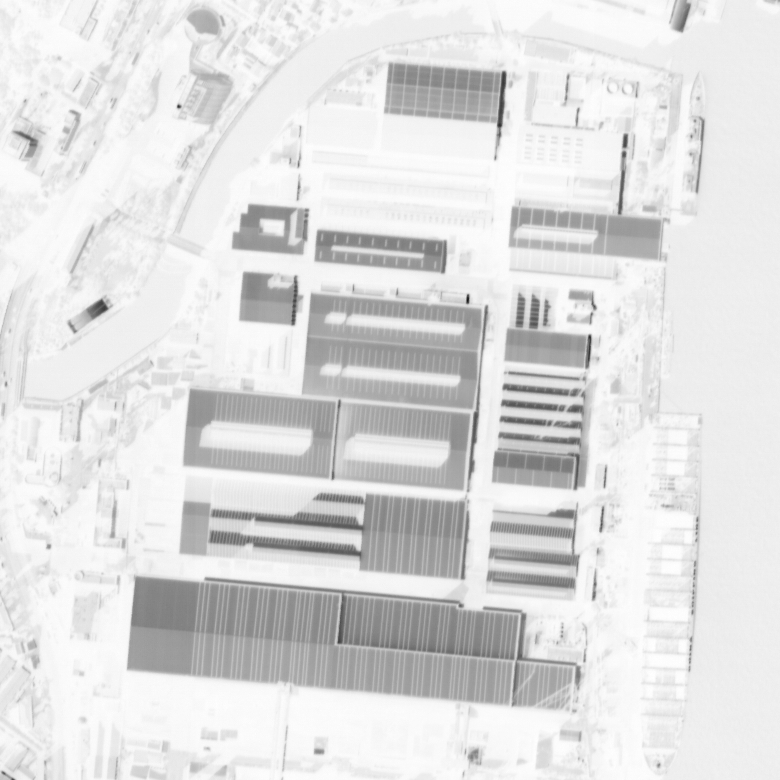

In [31]:
inverted_image = call_image_method('color_inversion', monochrome_image)
print('Инверсия')
display(Image.fromarray(inverted_image[:, :, 0]))


## ЛР1. Отражение изображения

Операция сохранена из ЛР1: отразить изображение относительно вертикальной оси, поменяв местами левую и правую стороны.


Отражение


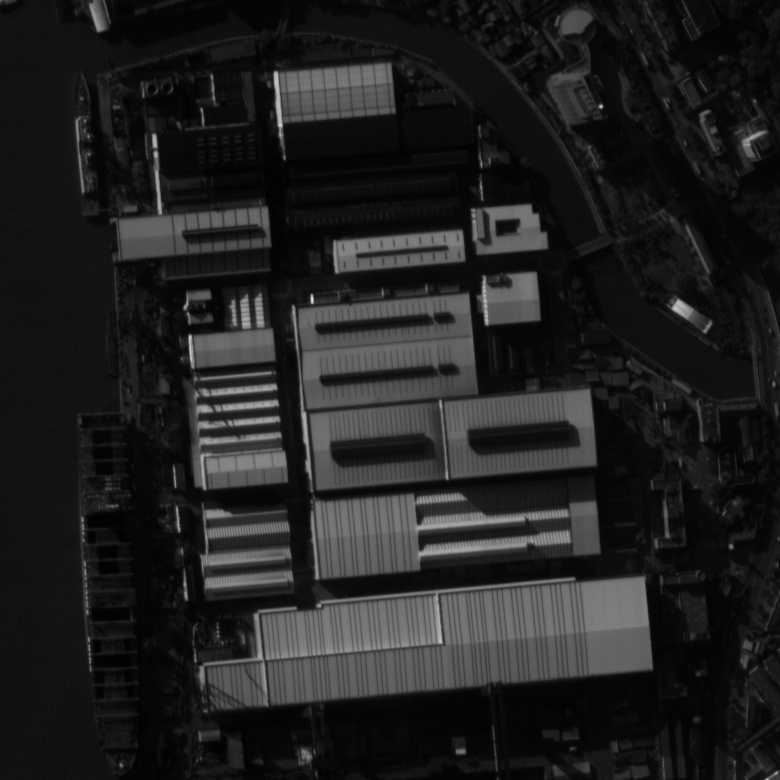

In [33]:
flipped_image = call_image_method('vertical_flip', monochrome_image)
print('Отражение')
display(Image.fromarray(flipped_image[:, :, 0]))


## ЛР1. Бинаризация изображения

Операция сохранена из ЛР1: пиксели с яркостью строго больше заданного порога сделать белыми, остальные — чёрными. Порог можно изменить перед запуском.


Бинаризация, порог 128


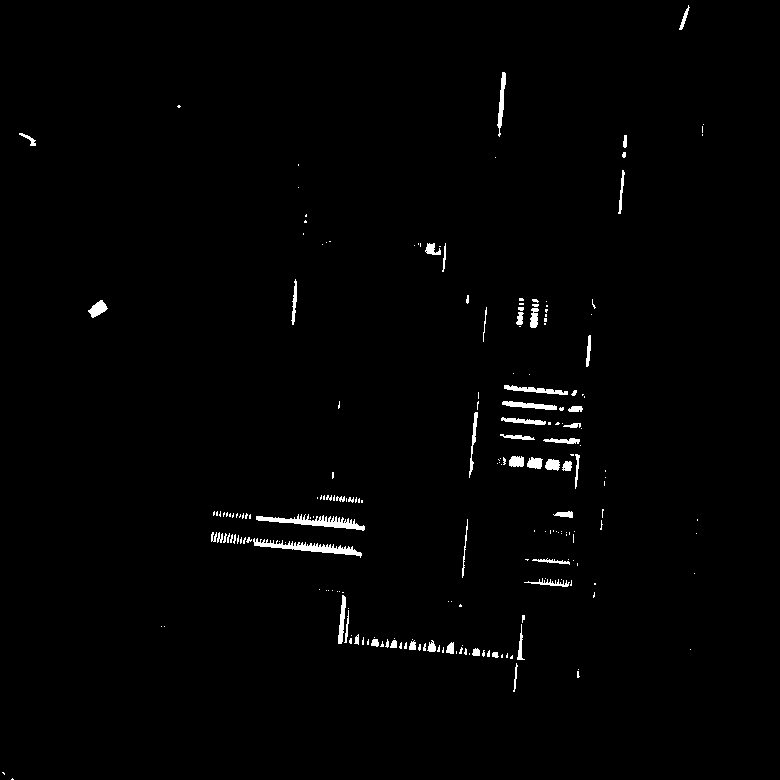

In [37]:
binarization_threshold = 128
binarized_image = call_image_method('binarize_image', monochrome_image, binarization_threshold)
print('Бинаризация, порог', binarization_threshold)
display(Image.fromarray(binarized_image[:, :, 0]))


## Задание 2. Бинаризация и процент пикселей выше порога

Требуется добавить новую серверную функцию: бинаризировать изображение и вернуть процент пикселей с яркостью строго больше порога. Здесь выводятся обработанное изображение и рассчитанный процент.


Бинаризация, порог 32


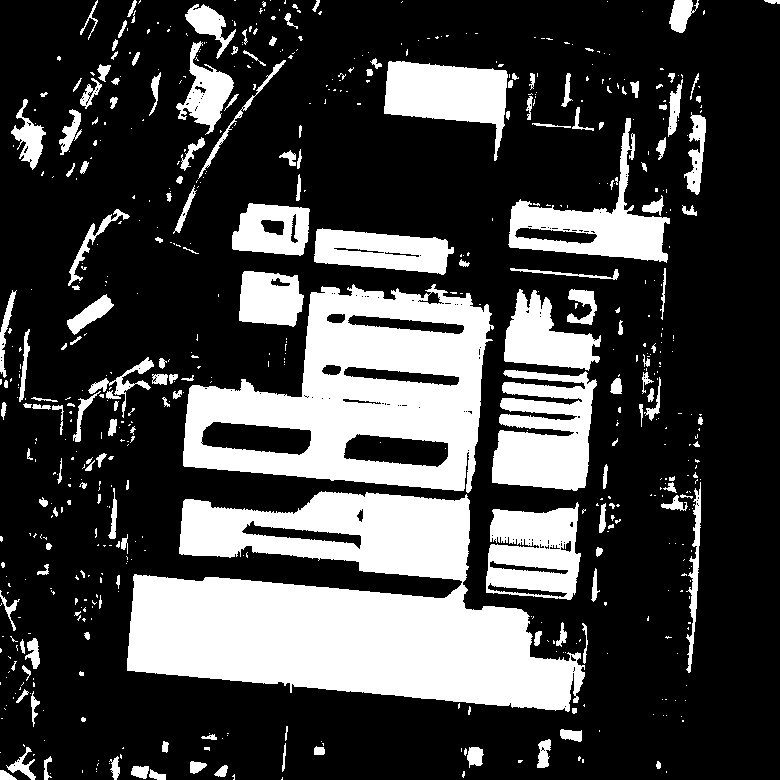

Пикселей выше порога: 26.99%


In [51]:
coverage_threshold = 32
coverage_binarization_result = main_service.binarize_with_coverage(pack_image(monochrome_image), coverage_threshold)
coverage_binarized_image = unpack_image(coverage_binarization_result['image'])
print('Бинаризация, порог', coverage_threshold)
display(Image.fromarray(coverage_binarized_image[:, :, 0]))
print('Пикселей выше порога: {:.2f}%'.format(coverage_binarization_result['above_threshold_percent']))


## Сервис статистики. Фильтрация по типу события и датам

Требуется получать журнал сервиса статистики и срез по типу операции и времени. Здесь запрашиваются события black_list_check с начальной даты до текущего времени. Сервер читает текущий журнал и архивы; source_log показывает файл каждой записи.


In [41]:
# Журнал запрашивается с фильтром по типу события и временному диапазону.
filter_end_time = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
blacklist_events = statistics_service.get_events('black_list_check', '2000-01-01 00:00:00', filter_end_time)
print('Записей black_list_check:', len(blacklist_events))
for event_record in blacklist_events:
    print(event_record)


Записей black_list_check: 20
{'timestamp': '2026-10-07 17:27:38', 'event_type': 'black_list_check', 'details': 'yes', 'source_log': 'events_log_20261014_144030.csv'}
{'timestamp': '2026-10-07 17:27:40', 'event_type': 'black_list_check', 'details': 'similar', 'source_log': 'events_log_20261014_144030.csv'}
{'timestamp': '2026-10-07 17:27:42', 'event_type': 'black_list_check', 'details': 'no', 'source_log': 'events_log_20261014_144030.csv'}
{'timestamp': '2026-10-07 17:28:26', 'event_type': 'black_list_check', 'details': 'yes', 'source_log': 'events_log_20261014_144030.csv'}
{'timestamp': '2026-10-07 17:28:27', 'event_type': 'black_list_check', 'details': 'no', 'source_log': 'events_log_20261014_144030.csv'}
{'timestamp': '2026-10-07 17:28:39', 'event_type': 'black_list_check', 'details': 'yes', 'source_log': 'events_log_20261014_144030.csv'}
{'timestamp': '2026-10-07 17:28:40', 'event_type': 'black_list_check', 'details': 'similar', 'source_log': 'events_log_20261014_144030.csv'}
{'time

## Сервис статистики. Демонстрация ротации

Требуется настраиваемый лимит числа записей: заполненный журнал сохранить под именем с датой и временем, затем вести запись в новый файл. Для демонстрации лимит временно равен 3 и добавляются 4 события, после чего лимит возвращается к 100. Повторный запуск добавляет новые события и может создавать архивы.


In [43]:
# Запускайте эту ячейку, когда нужно показать создание архивов.
statistics_service.set_max_log_records(3)
try:
    for event_number in range(4):
        statistics_service.add_event('rotation_test', f'event={event_number}')
finally:
    statistics_service.set_max_log_records(100)
print('Добавлены четыре события. Лимит возвращён к 100 записям.')


Добавлены четыре события. Лимит возвращён к 100 записям.


## Сервис статистики. Чтение событий из текущего журнала и архивов

Показать, что срез включает события из всех файлов, как уточнено для сдачи. Здесь читаются все события rotation_test; разные source_log позволяют увидеть их распределение по архивам и текущему журналу. Эта ячейка только читает записи.


In [45]:
all_rotation_events = statistics_service.get_events('rotation_test', '', '')
print('Срез по всем файлам журнала:', len(all_rotation_events))
for event_record in all_rotation_events:
    print(event_record)


Срез по всем файлам журнала: 20
{'timestamp': '2026-10-14 14:40:30', 'event_type': 'rotation_test', 'details': 'event=0', 'source_log': 'events_log_20261014_144030_1.csv'}
{'timestamp': '2026-10-14 14:40:30', 'event_type': 'rotation_test', 'details': 'event=1', 'source_log': 'events_log_20261014_144030_1.csv'}
{'timestamp': '2026-10-14 14:40:30', 'event_type': 'rotation_test', 'details': 'event=2', 'source_log': 'events_log_20261014_144030_1.csv'}
{'timestamp': '2026-10-14 14:40:30', 'event_type': 'rotation_test', 'details': 'event=3', 'source_log': 'events_log_20261014_144731.csv'}
{'timestamp': '2026-10-14 14:47:31', 'event_type': 'rotation_test', 'details': 'event=0', 'source_log': 'events_log_20261014_144731_1.csv'}
{'timestamp': '2026-10-14 14:47:31', 'event_type': 'rotation_test', 'details': 'event=1', 'source_log': 'events_log_20261014_144731_1.csv'}
{'timestamp': '2026-10-14 14:47:31', 'event_type': 'rotation_test', 'details': 'event=2', 'source_log': 'events_log_20261014_14473

## Полное содержимое текущего журнала и архивов

Запросить все события без ограничений по типу и времени. Для каждого файла отдельно показать все его записи и их количество. Ячейка только читает журналы и не вызывает ротацию. Файлы без событий не отображаются.


In [11]:
import pandas as pd

all_events = statistics_service.get_events('', '', '')
print('Всего событий во всех журналах:', len(all_events))
if all_events:
    events_table = pd.DataFrame(all_events)
    with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', None):
        for log_name, log_events in events_table.groupby('source_log', sort=True):
            print(log_name, '— записей:', len(log_events))
            display(log_events[['timestamp', 'event_type', 'details']].reset_index(drop=True))
else:
    print('В журналах пока нет событий.')


Всего событий во всех журналах: 49
events_log.csv — записей: 2


,timestamp,event_type,details
0,2026-10-14 19:34:10,rotation_test,event=2
1,2026-10-14 19:34:10,rotation_test,event=3


events_log_20261014_144030.csv — записей: 20


,timestamp,event_type,details
0,2026-10-07 17:27:38,black_list_check,yes
1,2026-10-07 17:27:40,black_list_check,similar
2,2026-10-07 17:27:42,black_list_check,no
3,2026-10-07 17:27:44,binarize_with_coverage,threshold=64; percentage=50.00
4,2026-10-07 17:28:26,black_list_check,yes
5,2026-10-07 17:28:27,black_list_check,no
6,2026-10-07 17:28:39,black_list_check,yes
7,2026-10-07 17:28:40,black_list_check,similar
8,2026-10-07 17:28:40,black_list_check,no
9,2026-10-07 17:28:41,binarize_with_coverage,threshold=64; percentage=50.00


events_log_20261014_144030_1.csv — записей: 3


...

,timestamp,event_type,details
0,2026-10-14 14:47:31,rotation_test,event=3
1,2026-10-14 15:05:10,black_list_check,yes
2,2026-10-14 15:05:10,black_list_check,similar
3,2026-10-14 15:05:10,black_list_check,no


events_log_20261014_191824_1.csv — записей: 3


,timestamp,event_type,details
0,2026-10-14 19:18:24,rotation_test,event=0
1,2026-10-14 19:18:24,rotation_test,event=1
2,2026-10-14 19:18:24,rotation_test,event=2


events_log_20261014_193410.csv — записей: 3


,timestamp,event_type,details
0,2026-10-14 19:18:24,rotation_test,event=3
1,2026-10-14 19:34:10,rotation_test,event=0
2,2026-10-14 19:34:10,rotation_test,event=1
